# Détection Classique des Candidats — Notebook 03

## Objectif
Tester et valider le pipeline de détection classique des candidats à l'embolie pulmonaire (module `O2_classical_detection`).
Ce notebook génère les fichiers `candidates.npy` nécessaires à l'étape de radiomics (notebook 04).

## Prérequis
- **Librairies** : `numpy`, `matplotlib`, `pandas`, `scikit-image`, `seaborn`
- **Données** : `data/raw/` avec volumes DICOM bruts (mode `force_raw=True` obligatoire pour O2)
- **Modules** : `src.O1_preprocessing.loader`, `src.O2_classical_detection.*`

## Étapes principales
1. [Imports & configuration](#1-imports--configuration)
2. [Inventaire RAW & configuration du détecteur](#2-inventaire-raw--configuration-du-d%C3%A9tecteur)
3. [Test unitaire sur 1 patient](#3-test-unitaire-sur-1-patient)
4. [Visualisation des candidats](#4-visualisation-des-candidats)
5. [Traitement batch (35 patients)](#5-traitement-batch-35-patients)

> **Lien avec le notebook suivant :** Les `candidates.npy` générés en cellule 5 sont requis par `04_radiomics_demo.ipynb` pour construire le dataset ML.

> ⚠️ **Règle absolue :** O2 tourne **toujours** en mode RAW (`force_raw=True`). Les seuils HU sont calibrés pour les données DICOM brutes [-1024, 3071].


## 1. Imports & configuration

### 1.1 Imports et configuration du chemin racine

Import des librairies scientifiques et des modules de détection classique.
Configuration du chemin racine pour l'accès aux modules `src/`.


In [1]:
# ==============================================================
# CELLULE 1  Imports
# ==============================================================
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

root_path = os.path.abspath(os.path.join('..'))
if root_path not in sys.path:
    sys.path.insert(0, root_path)

from src.O1_preprocessing.loader import get_available_patients, load_patient_data
from src.O2_classical_detection.detector import ClassicalDetector

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
print('✅ Imports OK')


✅ Imports OK


## 2. Inventaire RAW & configuration du détecteur

### 2.1 Inventaire des données brutes et initialisation du détecteur

Recensement des patients disposant de données DICOM brutes **et** d'un masque GT.
Initialisation du `ClassicalCandidateDetector` avec les seuils HU calibrés pour données brutes.

> **Règle critique :** `force_raw=True` est impératif — les seuils HU sont calibrés pour [-1024, 3071].
> **Sortie :** `raw_inventory` et instance `detector` prête à l'emploi.


In [3]:
# ==============================================================
# CELLULE 2 : Inventaire RAW + Config detecteur
# REGLE : force_raw=True TOUJOURS pour O2
# Les seuils HU sont calibres pour donnees DICOM brutes [-1024, 3071]
# ==============================================================
DATA_DIR      = Path.cwd().parent / 'data'
PROCESSED_DIR = DATA_DIR / 'processed'

assert DATA_DIR.exists(),          f'data/ introuvable : {DATA_DIR}'
assert (DATA_DIR / 'raw').exists(), 'data/raw/ introuvable'

raw_inventory = get_available_patients(str(DATA_DIR), force_raw=True)
n_pat = len(raw_inventory['with_both'])
mode  = 'PROCESSED' if raw_inventory.get('use_processed', False) else 'RAW'
print(f'Patients RAW disponibles : {n_pat}')
print(f'Mode : {mode} ')
assert mode == 'RAW', f'Erreur mode={mode}, force_raw=True devrait donner RAW'

# Seuils HU physiologiques (valides pour donnees RAW)
CONFIG = {
    'lung_hu_threshold'   : -400,  # separation air / tissus mous
    'threshold_method'    : 'percentile',
    'threshold_percentile': 85,    # top 15% densites dans les poumons
    'min_hu'              : 20,    # plancher thrombus/vaisseau
    'max_hu'              : 400,   # exclut l'os
    'min_candidate_volume': 10,
    'max_candidate_volume': 5000
}
detector = ClassicalDetector(CONFIG)
print('\nConfig detecteur :')
for k, v in CONFIG.items():
    print(f'  {k:28s}: {v}')


2026-10-10 16:18:06,318 - src.O1_preprocessing.loader - INFO - 📂 Mode : Données BRUTES (raw) - Exploration
2026-10-10 16:18:06,358 - src.O1_preprocessing.loader - INFO - 📁 Volumes trouvés : 35 patients
2026-10-10 16:18:06,360 - src.O1_preprocessing.loader - INFO - 📁 Masques trouvés dans f:\Nouveau dossier\Projets\Projet_detection_embolie_pulmonaire\data\raw\GroundTruth: 35 fichiers
2026-10-10 16:18:06,361 - src.O1_preprocessing.loader - INFO - 📊 Inventaire : 35 patients avec Volume + Masque.


Patients RAW disponibles : 35
Mode : RAW 

Config detecteur :
  lung_hu_threshold           : -400
  threshold_method            : percentile
  threshold_percentile        : 85
  min_hu                      : 20
  max_hu                      : 400
  min_candidate_volume        : 10
  max_candidate_volume        : 5000


## 3. Test unitaire sur 1 patient

### 3.1 Détection sur un patient avec logs de diagnostic

Exécution du pipeline de détection sur le premier patient de l'inventaire :
1. Segmentation des poumons (`segment_lungs`)
2. Seuillage adaptatif (`adaptive_threshold`)
3. Détection et labellisation des candidats

Les logs permettent de diagnostiquer les problèmes (masque poumon vide, seuils HU inadaptés).

> **Sortie :** `result` contenant `n_candidates`, `candidates_mask`, et les coordonnées des candidats.
> **Point d'attention :** si `n_candidates == 0`, vérifier que le masque poumon est non vide (cf. logs).


In [4]:
# ==============================================================
# CELLULE 3: Test sur 1 patient avec logs de diagnostic
# ==============================================================
from src.O2_classical_detection.lung_segmentation import segment_lungs
from src.O2_classical_detection.thresholding import adaptive_threshold

test_id = raw_inventory['with_both'][0]
print(f'Test avec : {test_id}')

vol, mask_gt, meta = load_patient_data(test_id, raw_inventory)
print(f'Volume : {vol.shape}  HU : [{vol.min():.0f}, {vol.max():.0f}]')

spacing = (
    meta.get('slice_spacing', 1.0),
    meta.get('spacing', [1.0, 1.0])[0],
    meta.get('spacing', [1.0, 1.0])[1]
) if meta else (1.0, 1.0, 1.0)
print(f'Spacing : Z={spacing[0]:.2f}  Y={spacing[1]:.2f}  X={spacing[2]:.2f} mm')

# Etape 1 : segmentation poumons
lung_mask_diag = segment_lungs(vol, hu_threshold=CONFIG['lung_hu_threshold'])
n_lung = lung_mask_diag.sum()
print(f'[1] Masque poumon  : {n_lung:,} voxels ({100*n_lung/lung_mask_diag.size:.1f}%)')
if n_lung == 0:
    print('    PROBLEME : masque poumon vide - verifier le volume et lung_hu_threshold')

# Etape 2 : seuillage adaptatif
cand_diag = adaptive_threshold(
    vol, lung_mask_diag,
    method=CONFIG['threshold_method'],
    percentile=CONFIG['threshold_percentile'],
    min_hu=CONFIG['min_hu'], max_hu=CONFIG['max_hu']
)
print(f'[2] Candidats bruts : {cand_diag.sum():,} voxels')

# Etape 3 : detection complete
result = detector.detect(vol, spacing=spacing)
n_cand = result['n_candidates']
n_vox  = result['total_candidate_voxels']
print(f'[3] RESULTATS FINAUX :')
print(f'    Poumons   : {result["lung_mask"].sum():,} voxels')
print(f'    Candidats : {n_cand}  ({n_vox:,} voxels)')

if len(result['candidates_df']) > 0:
    print(f'\nTop 5 candidats par volume :')
    display(result['candidates_df'].nlargest(5, 'volume_voxels')[
        ['region_id', 'volume_voxels', 'intensity_mean', 'sphericity']
    ])
else:
    print('0 candidats - voir logs ci-dessus pour diagnostiquer')


Test avec : PAT001


2026-10-10 16:19:41,538 - src.O1_preprocessing.loader - INFO - ℹ️ DICOM metadata: RescaleSlope=1, RescaleIntercept=-1024
2026-10-10 16:19:41,606 - src.O1_preprocessing.loader - INFO -    Plage HU après conversion: [-1024.0, 3071.0]
2026-10-10 16:19:41,607 - src.O1_preprocessing.loader - INFO - ✅ Volume chargé : (201, 512, 512) de PAT001
2026-10-10 16:19:41,914 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé avec clé 'Mask'
2026-10-10 16:19:41,918 - src.O1_preprocessing.loader - INFO - Transpose appliqué: (512, 512, 201) → (201, 512, 512)
2026-10-10 16:19:41,919 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé : (201, 512, 512)
2026-10-10 16:19:41,938 - src.O2_classical_detection.lung_segmentation - INFO - 🫁 Segmentation des poumons (méthode: threshold)


Volume : (201, 512, 512)  HU : [-1024, 3071]
Spacing : Z=1.00  Y=0.62  X=0.62 mm


2026-10-10 16:20:11,720 - src.O2_classical_detection.lung_segmentation - INFO - ✅ Masque pulmonaire: 8159612 voxels (15.5% du volume), 2 région(s)
2026-10-10 16:20:11,773 - src.O2_classical_detection.thresholding - INFO - 🔍 Seuillage adaptatif (méthode: percentile)


[1] Masque poumon  : 8,159,612 voxels (15.5%)


2026-10-10 16:20:12,458 - src.O2_classical_detection.thresholding - INFO -    Lissage gaussien (sigma=1.0) appliqué sur ROI de taille (187, 303, 431)
2026-10-10 16:20:12,562 - src.O2_classical_detection.thresholding - INFO -    Seuil percentile 85: 42.8 HU
2026-10-10 16:20:12,654 - src.O2_classical_detection.thresholding - INFO -    Seuil appliqué: 42.8 - 400 HU
2026-10-10 16:20:15,310 - src.O2_classical_detection.thresholding - INFO - ✅ 1135152 voxels candidats détectés (2.154% du volume)
2026-10-10 16:20:15,310 - src.O2_classical_detection.thresholding - INFO -    211 régions candidates identifiées
2026-10-10 16:20:16,025 - src.O2_classical_detection.thresholding - INFO -    Tailles: min=7, moy=5380, max=791494
2026-10-10 16:20:16,098 - src.O2_classical_detection.detector - INFO - 🚀 Démarrage de la détection classique...
2026-10-10 16:20:16,099 - src.O2_classical_detection.lung_segmentation - INFO - 🫁 Segmentation des poumons (méthode: threshold)


[2] Candidats bruts : 1,135,152 voxels


2026-10-10 16:20:45,057 - src.O2_classical_detection.lung_segmentation - INFO - ✅ Masque pulmonaire: 8159612 voxels (15.5% du volume), 2 région(s)
2026-10-10 16:20:45,060 - src.O2_classical_detection.thresholding - INFO - 🔍 Seuillage adaptatif (méthode: percentile)
2026-10-10 16:20:45,745 - src.O2_classical_detection.thresholding - INFO -    Lissage gaussien (sigma=1.0) appliqué sur ROI de taille (187, 303, 431)
2026-10-10 16:20:45,830 - src.O2_classical_detection.thresholding - INFO -    Seuil percentile 85: 42.8 HU
2026-10-10 16:20:45,923 - src.O2_classical_detection.thresholding - INFO -    Seuil appliqué: 42.8 - 400 HU
2026-10-10 16:20:48,641 - src.O2_classical_detection.thresholding - INFO - ✅ 1135152 voxels candidats détectés (2.154% du volume)
2026-10-10 16:20:48,641 - src.O2_classical_detection.thresholding - INFO -    211 régions candidates identifiées
2026-10-10 16:20:49,362 - src.O2_classical_detection.thresholding - INFO -    Tailles: min=7, moy=5380, max=791494
2026-10-10 

[3] RESULTATS FINAUX :
    Poumons   : 8,159,612 voxels
    Candidats : 139  (26,577 voxels)

Top 5 candidats par volume :


,region_id,volume_voxels,intensity_mean,sphericity
83,84,4295.0,138.136673,0
45,46,3843.0,149.499863,0
58,59,1938.0,89.782768,0
48,49,1635.0,72.012840,0
87,88,1607.0,113.321098,0


## 4. Visualisation des candidats

### 4.1 Superposition : volume HU + masque poumon + candidats O2 + GT

Affichage de la coupe contenant le plus de candidats détectés, avec superposition de :
- **Colonne 1** : volume HU brut (niveaux de gris)
- **Colonne 2** : masque de segmentation pulmonaire
- **Colonne 3** : candidats O2 (vert) et annotations GT (rouge)

> Permet de valider visuellement la qualité de la détection avant le traitement batch.


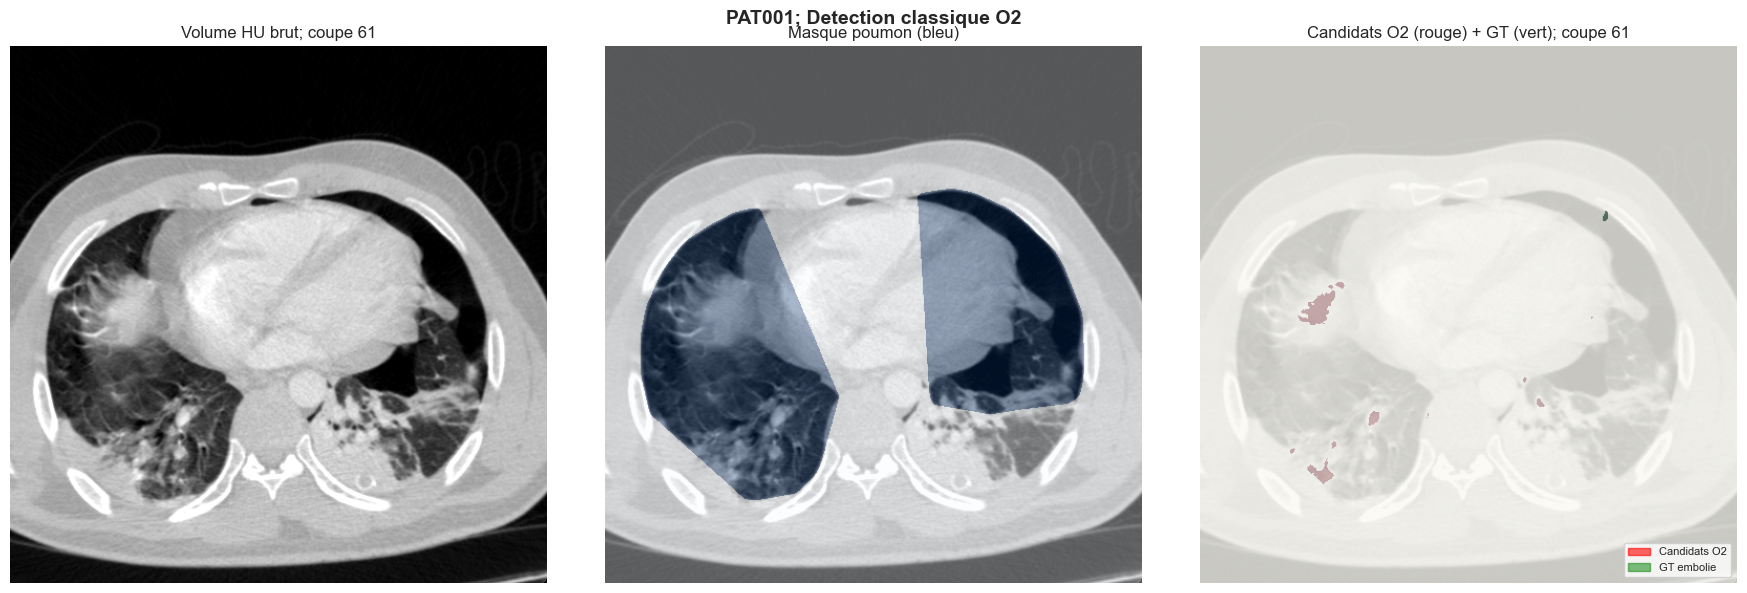

✅ Coupe 61 : 1078 voxels candidats


In [6]:
# ==============================================================
# CELLULE 4 : Visualisation : poumons + candidats O2 + GT
# ==============================================================
import matplotlib.patches as mpatches

if result['n_candidates'] > 0 and vol is not None:
    # Coupe avec le plus de candidats
    cand_per_slice = result['candidates_mask'].sum(axis=(1, 2))
    best = int(cand_per_slice.argmax())

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # 1. Volume HU brut
    axes[0].imshow(vol[best], cmap='gray', vmin=-1000, vmax=400)
    axes[0].set_title(f'Volume HU brut; coupe {best}')
    axes[0].axis('off')

    # 2. Masque poumons
    axes[1].imshow(vol[best], cmap='gray', vmin=-1000, vmax=400)
    axes[1].imshow(result['lung_mask'][best], cmap='Blues', alpha=0.35)
    axes[1].set_title('Masque poumon (bleu)')
    axes[1].axis('off')

    # 3. Candidats O2 (rouge) + GT (vert)
    axes[2].imshow(vol[best], cmap='gray', vmin=-1000, vmax=400)
    if result['candidates_mask'][best].max() > 0:
        axes[2].imshow(result['candidates_mask'][best], cmap='Reds', alpha=0.6)
    if mask_gt is not None and mask_gt[best].max() > 0:
        axes[2].imshow(mask_gt[best], cmap='Greens', alpha=0.5)
    p_red   = mpatches.Patch(color='red',   alpha=0.6, label='Candidats O2')
    p_green = mpatches.Patch(color='green', alpha=0.5, label='GT embolie')
    axes[2].legend(handles=[p_red, p_green], loc='lower right', fontsize=8)
    axes[2].set_title(f'Candidats O2 (rouge) + GT (vert); coupe {best}')
    axes[2].axis('off')

    plt.suptitle(f'{test_id}; Detection classique O2', fontsize=14, fontweight='bold')
    plt.tight_layout()
    import os
    os.makedirs('../figures/classical_detection', exist_ok=True)
    plt.savefig(f'../figures/classical_detection/{test_id}_detection.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'✅ Coupe {best} : {int(cand_per_slice[best])} voxels candidats')
else:
    print('⚠️ Pas de candidats a visualiser.')


## 5. Traitement batch (35 patients)

### 5.1 Détection et sauvegarde sur l'ensemble des patients

Exécution du pipeline de détection sur les 35 patients disponibles.
Pour chaque patient, génère et sauvegarde `candidates.npy` dans `data/processed/PATxxx/`.

> **Durée estimée :** quelques minutes selon le nombre de patients et la puissance machine.
> **Sortie :** fichiers `candidates.npy` dans chaque dossier patient — **requis par le notebook 04**.
> Mettre `force=True` pour écraser des fichiers existants.


In [7]:
# ==============================================================
# CELLULE 5  BATCH : Detection sur les 35 patients
#             Genere candidates.npy dans data/processed/PATxxx/
#             Necessaire pour O3 (build_ml_dataset.py)
# ==============================================================
# Mettre force=True pour ecraser des candidates.npy existants
success, skipped = 0, 0

for pid in raw_inventory['with_both']:
    res = detector.detect_and_save(
        patient_id    = pid,
        processed_dir = str(PROCESSED_DIR),
        raw_inventory = raw_inventory,
        force         = False
    )
    if res is None:
        skipped += 1
    else:
        success += 1

print(f'Batch termine :')
print(f'  Traites  : {success}')
print(f'  Skippes  : {skipped}  (candidates.npy deja presents)')
print(f'Sortie    : {PROCESSED_DIR}')


2026-10-10 16:24:42,678 - src.O2_classical_detection.detector - INFO - 📦 Chargement RAW de PAT001...
2026-10-10 16:24:43,714 - src.O1_preprocessing.loader - INFO - ℹ️ DICOM metadata: RescaleSlope=1, RescaleIntercept=-1024
2026-10-10 16:24:43,736 - src.O1_preprocessing.loader - INFO -    Plage HU après conversion: [-1024.0, 3071.0]
2026-10-10 16:24:43,738 - src.O1_preprocessing.loader - INFO - ✅ Volume chargé : (201, 512, 512) de PAT001
2026-10-10 16:24:43,960 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé avec clé 'Mask'
2026-10-10 16:24:43,962 - src.O1_preprocessing.loader - INFO - Transpose appliqué: (512, 512, 201) → (201, 512, 512)
2026-10-10 16:24:43,964 - src.O1_preprocessing.loader - INFO - ✅ Masque chargé : (201, 512, 512)
2026-10-10 16:24:43,965 - src.O2_classical_detection.detector - INFO -    Spacing DICOM : Z=1.00 Y=0.62 X=0.62 mm
2026-10-10 16:24:43,966 - src.O2_classical_detection.detector - INFO - 🚀 Démarrage de la détection classique...
2026-10-10 16:24:43,966 -

Batch termine :
  Traites  : 35
  Skippes  : 0  (candidates.npy deja presents)
Sortie    : f:\Nouveau dossier\Projets\Projet_detection_embolie_pulmonaire\data\processed


### Notes

• **O2 tourne toujours en mode RAW** (`force_raw=True`); seuils HU calibrés pour DICOM brut [-1024, 3071]

• Les `candidates.npy` générés par la cellule 5 (batch) sont requis par O3 (`build_ml_dataset.py`)

• Si 0 candidat : lire les logs de la cellule 3; masque poumon > 0 ?

• Prochaine étape : corriger la double normalisation GLCM dans `src/O3_radiomics/feature_extractor.py` puis lancer `build_ml_dataset.py`
